# 01 · How stale can a quantile forecast be? The freshness budget on simulated data

**Block 5 · W44, notebook 1 of 2.** A forecast service publishes quantiles (the median, the 80th, the 95th
percentile), and refits its model every $k$ hours. The plan claims the tolerable staleness depends strongly on
*which* quantile is served: a week for the median, a day for the 95th percentile, a **factor 7**. This notebook
rebuilds that claim step by step, then checks it.

| § | Question | Short answer |
|---|---|---|
| 1 | What is a quantile forecast, and how do we score it? | A threshold the truth should stay below with probability tau; scored by the pinball loss. |
| 2 | What does the plan measure? | The largest cadence $k_{max}$ at which the model still beats a seasonal naive, per quantile: 168 / 120 / 24. |
| 3 | Why does the 95th percentile degrade so fast? | Its quantiles are under-covered, more so as the model ages. |
| 4 | Is the baseline fair? | No: it reads 48 hours of data the model is not allowed to read. |
| 5 | What is left once both are fixed? | A factor 2, stable over five seeds. |
| 6 | And the stability clause? | It depends on how the quantiles are built, not only on the cadence. |

> **How to read this notebook.** Callouts follow a fixed code:
> **Intuition**, the idea without equations · **Example**, a worked number ·
> **Watch out**, the trap to avoid · **Takeaway**, the memo to keep.

In [1]:

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from w44_retraining import freshness_study as fs
from w44_retraining import viz
from w44_retraining.freshness import TAUS, closed_lag
from w44_retraining.metrics import pinball
from w44_retraining.park import make_park

viz.setup()
export = viz.exporter("../figures")


def show(headers, rows):
    """Render a small table as Markdown (no pandas dependency)."""
    lines = ["| " + " | ".join(map(str, headers)) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(map(str, r)) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

## 1. Quantile forecasts and the pinball loss

**Question.** What does "the 0.95 quantile forecast" promise, and how do we score it?

A $\tau$-quantile forecast $q$ is a threshold the truth $y$ should stay below with probability $\tau$. Its
**coverage** is the share of targets that actually fall below it: a good 0.95 quantile covers 95%. It is scored
by the **pinball loss**, which charges an asymmetric price:

$$\ell_\tau(y, q) = \begin{cases} \tau\,(y - q) & \text{if } y \ge q \text{ (under-forecast)} \\
(1 - \tau)\,(q - y) & \text{if } y < q \text{ (over-forecast)} \end{cases}$$

> **Example.** For $\tau = 0.95$, being 1 unit too low costs 0.95, being 1 unit too high costs 0.05. The loss is
> minimised, on average, exactly at the true 95th percentile: that is why it is the right score for a quantile.

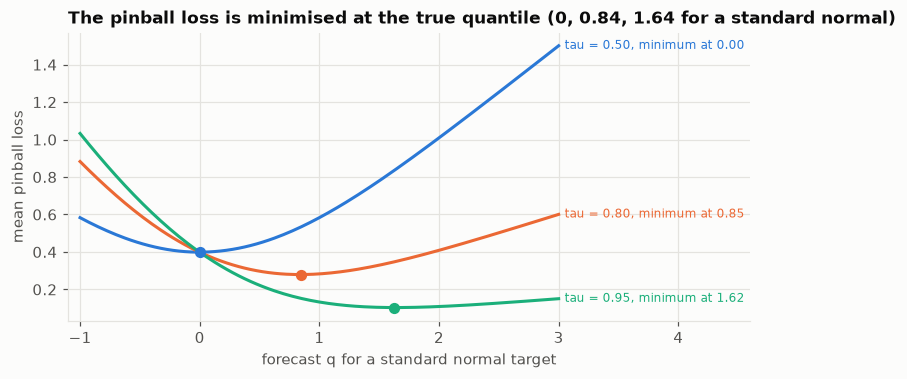

In [2]:
rng = np.random.default_rng(0)
y = rng.normal(size=100_000)
grid = np.linspace(-1, 3, 161)
fig, ax = plt.subplots(figsize=(8, 3.4))
for tau, c in zip(TAUS, viz.SERIES, strict=True):
    loss = [pinball(y, np.full_like(y, q), tau).mean() for q in grid]
    best = grid[int(np.argmin(loss))]
    ax.plot(grid, loss, color=c)
    ax.scatter([best], [min(loss)], color=c, s=40, zorder=3)
    ax.text(grid[-1] + 0.05, loss[-1], f"tau = {tau:.2f}, minimum at {best:.2f}", color=c, fontsize=8,
            va="center")
ax.set_xlabel("forecast q for a standard normal target"); ax.set_ylabel("mean pinball loss")
ax.set_xlim(-1.1, 4.6)
ax.set_title("The pinball loss is minimised at the true quantile (0, 0.84, 1.64 for a standard normal)")
plt.show()

> **Watch out.** Pinball losses at different $\tau$ live on different scales (the 0.95 loss is smaller because
> most targets fall below the quantile and cost little). Compare a model with a baseline **at the same $\tau$**,
> never across $\tau$.

## 2. The plan's chain, reproduced

**Setup.** 200 simulated hourly series, 2,400 hours each (seed 544): a level with sudden breaks and a daily
profile whose amplitude drifts slowly. The served model is the one of block 2: the mean of the last 240 hours
plus a 24-hour profile. Two rules of production are built in:

- **closing lag** $d = 48$: the actuals of the last 48 hours are not final yet, so a refit at time $t$ uses
  data up to $t - 48$;
- the model is **refit every $k$ hours**, from $k = 1$ (continuously) to $k = 720$ (monthly).

The plan builds quantiles as point forecast $+ z_\tau \times sd$, with $sd$ the standard deviation of the
residuals inside the training window (the **gaussian** method), and compares them with a **seasonal naive**:
tomorrow at 14:00 = today at 14:00, with a spread taken from past day-to-day differences.

The study below runs every cadence, both quantile methods, both baselines and five seeds (about three minutes).

In [3]:
out = fs.study()
park = make_park(fs.SPEC)

In [4]:
g = out["loss"]["gaussian"]
show(["k (hours)", "refits", *[f"pinball tau={t:.2f}" for t in TAUS], "coverage tau=0.95"],
     [(k, out["refits"][k], *(f"{g[k][t]:.4f}" for t in TAUS), f"{out['cov']['gaussian'][k][0.95]:.3f}")
      for k in fs.KS])
show(["baseline", *[f"tau={t:.2f}" for t in TAUS]],
     [("seasonal naive (plan)", *(f"{out['base']['snaive'][t]:.4f}" for t in TAUS))])
km = out["k_max"]["gaussian", "snaive"]
print("k_max (largest k that still beats the naive):", {t: km[t] for t in TAUS},
      f"-> ratio {km[0.5] / km[0.95]:.1f}")

| k (hours) | refits | pinball tau=0.50 | pinball tau=0.80 | pinball tau=0.95 | coverage tau=0.95 |
|---|---|---|---|---|---|
| 1 | 2063 | 0.2544 | 0.1827 | 0.0736 | 0.909 |
| 12 | 171 | 0.2561 | 0.1841 | 0.0746 | 0.907 |
| 24 | 85 | 0.2579 | 0.1857 | 0.0757 | 0.906 |
| 36 | 57 | 0.2598 | 0.1873 | 0.0767 | 0.905 |
| 48 | 42 | 0.2616 | 0.1889 | 0.0778 | 0.903 |
| 72 | 28 | 0.2652 | 0.1922 | 0.0802 | 0.900 |
| 120 | 17 | 0.2726 | 0.1990 | 0.0849 | 0.894 |
| 168 | 12 | 0.2795 | 0.2046 | 0.0888 | 0.890 |
| 336 | 6 | 0.3039 | 0.2259 | 0.1047 | 0.872 |
| 720 | 2 | 0.3594 | 0.2782 | 0.1453 | 0.835 |

| baseline | tau=0.50 | tau=0.80 | tau=0.95 |
|---|---|---|---|
| seasonal naive (plan) | 0.2880 | 0.2032 | 0.0758 |

k_max (largest k that still beats the naive): {0.5: 168, 0.8: 120, 0.95: 24} -> ratio 7.0


This is the plan's result, to the digit: $k_{max}$ = 168 hours at the median, 120 at 0.80, **24 at 0.95**. The
median tolerates a week of staleness; the 95th percentile, one day. The plan writes it into the service contract
as a freshness budget per quantile.

> **Intuition.** It is plausible: a stale model is biased (the level moved since the last refit), and a bias
> hurts the extreme quantiles more than the median, because they are already close to the edge of the
> distribution. But two other mechanisms can produce the same pattern. The next two sections isolate them.

## 3. First artefact: the tails are under-covered, and more so as the model ages

**Question.** Does the 0.95 quantile actually cover 95% of the targets?

The gaussian method uses the residual spread **inside the training window**: the error of a model on the data it
was fit on. Out of sample, and as the model ages, the error grows (the level drifts away from the fitted mean),
but the quantile does not widen. An alternative, **conformal** quantiles, places the quantile at the empirical
$\tau$-quantile of the model's own past errors, using only errors that are already *closed* (their target is at
least 48 hours old). It is calibrated by construction on what the model actually does.

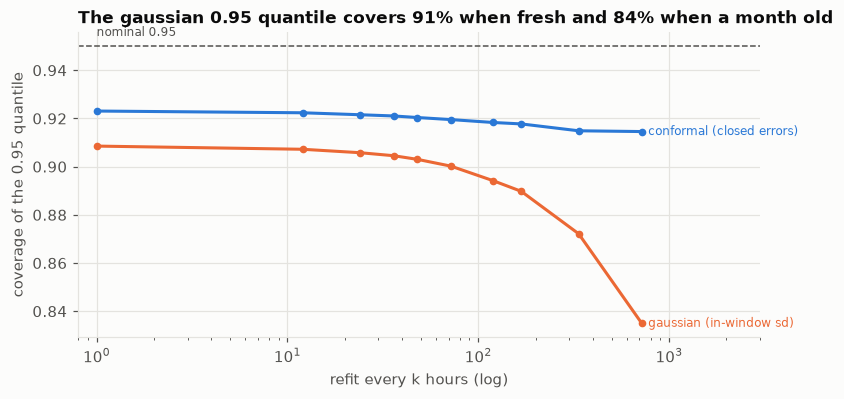

| k | gaussian coverage | conformal coverage |
|---|---|---|
| 1 | 0.909 | 0.923 |
| 12 | 0.907 | 0.922 |
| 24 | 0.906 | 0.922 |
| 36 | 0.905 | 0.921 |
| 48 | 0.903 | 0.920 |
| 72 | 0.900 | 0.920 |
| 120 | 0.894 | 0.918 |
| 168 | 0.890 | 0.918 |
| 336 | 0.872 | 0.915 |
| 720 | 0.835 | 0.915 |

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ks = np.array(fs.KS)
for meth, c, lab in (("gaussian", viz.ORANGE, "gaussian (in-window sd)"),
                     ("conformal", viz.BLUE, "conformal (closed errors)")):
    cov = [out["cov"][meth][k][0.95] for k in fs.KS]
    ax.plot(ks, cov, color=c, marker="o", ms=4)
    ax.text(ks[-1] * 1.08, cov[-1], lab, color=c, fontsize=8, va="center")
ax.axhline(0.95, color=viz.TEXT_2, ls="--", lw=1)
ax.text(1, 0.953, "nominal 0.95", color=viz.TEXT_2, fontsize=8, va="bottom")
ax.set_xscale("log"); ax.set_xlim(0.8, 3000)
ax.set_xlabel("refit every k hours (log)"); ax.set_ylabel("coverage of the 0.95 quantile")
ax.set_title("The gaussian 0.95 quantile covers 91% when fresh and 84% when a month old")
export(fig, "coverage_vs_cadence"); plt.show()
show(["k", "gaussian coverage", "conformal coverage"],
     [(k, f"{out['cov']['gaussian'][k][0.95]:.3f}", f"{out['cov']['conformal'][k][0.95]:.3f}") for k in fs.KS])

In [6]:
deg = {m: {t: out["loss"][m][720][t] / out["loss"][m][1][t] - 1 for t in TAUS} for m in ("gaussian", "conformal")}
show(["quantiles", *[f"degradation k=1 -> 720, tau={t:.2f}" for t in TAUS]],
     [(m, *(f"{deg[m][t]:+.0%}" for t in TAUS)) for m in deg])

| quantiles | degradation k=1 -> 720, tau=0.50 | degradation k=1 -> 720, tau=0.80 | degradation k=1 -> 720, tau=0.95 |
|---|---|---|---|
| gaussian | +41% | +52% | +97% |
| conformal | +19% | +19% | +21% |

> **Takeaway.** With gaussian quantiles, going from continuous to monthly refits worsens the 0.95 pinball by
> +97% against +41% at the median: the "tails suffer more" story. With conformal quantiles the degradation is
> +19%, +19%, +21%: **almost the same for every quantile**. Most of the extra damage at 0.95 was a calibration
> failure (the quantile not widening as the model ages), not a property of the quantile.

> **Watch out.** Conformal is not perfect either: it covers about 0.92, not 0.95. It is exact only when errors are
> exchangeable (past errors look like future ones), and level breaks violate that. It fixes the *drift* of
> coverage with model age, not its level.

## 4. Second artefact: the baseline reads data the model may not

**Question.** At origin $t_0$, which observations does each competitor use?

The plan's seasonal naive forecasts hour $t_0 + h$ with the same hour one day earlier, $y_{t_0 + h - 24}$. For the
24 hours ahead that means reading $y_{t_0 - 23}, \dots, y_{t_0}$. Under a 48-hour closing lag those values are
**not final yet**: the model is forbidden from using them, the baseline is not. The fair version uses the same
hour three days earlier (lag 72), whose newest value is $t_0 - 48$.

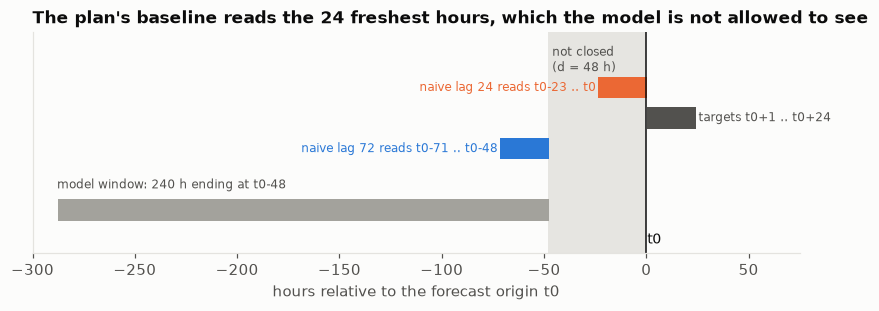

In [7]:
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.axvspan(-48, 0, color=viz.GRID, alpha=0.9, lw=0)
ax.text(-46, 2.45, "not closed\n(d = 48 h)", ha="left", color=viz.TEXT_2, fontsize=8, va="center")
ax.barh(2, 24, left=-23 - 0.5, height=0.35, color=viz.ORANGE)
ax.text(-24.5, 2, "naive lag 24 reads t0-23 .. t0", ha="right", va="center", color=viz.ORANGE, fontsize=8)
ax.barh(1, 24, left=-71 - 0.5, height=0.35, color=viz.BLUE)
ax.text(-72.5, 1, "naive lag 72 reads t0-71 .. t0-48", ha="right", va="center", color=viz.BLUE, fontsize=8)
ax.barh(0, 240, left=-48 - 240 + 0.5, height=0.35, color=viz.MUTED)
ax.text(-48 - 240, 0.35, "model window: 240 h ending at t0-48", color=viz.TEXT_2, fontsize=8)
ax.barh(1.5, 24, left=0.5, height=0.35, color=viz.TEXT_2)
ax.text(25.5, 1.5, "targets t0+1 .. t0+24", va="center", color=viz.TEXT_2, fontsize=8)
ax.axvline(0, color=viz.TEXT, lw=1); ax.text(0.5, -0.55, "t0", fontsize=9)
ax.set_xlim(-300, 75); ax.set_ylim(-0.7, 2.9); ax.set_yticks([]); ax.grid(False)
ax.set_xlabel("hours relative to the forecast origin t0")
ax.set_title("The plan's baseline reads the 24 freshest hours, which the model is not allowed to see")
export(fig, "baseline_leak_timeline"); plt.show()

In [8]:
show(["baseline", *[f"pinball tau={t:.2f}" for t in TAUS], "coverage 0.95"],
     [("naive lag 24 (plan)", *(f"{out['base']['snaive'][t]:.4f}" for t in TAUS), f"{out['base_cov'][0.95]:.3f}"),
      (f"naive lag {closed_lag(24, 24, 48)} (closed)", *(f"{out['base']['snaive_closed'][t]:.4f}" for t in TAUS),
       "")])

| baseline | pinball tau=0.50 | pinball tau=0.80 | pinball tau=0.95 | coverage 0.95 |
|---|---|---|---|---|
| naive lag 24 (plan) | 0.2880 | 0.2032 | 0.0758 | 0.948 |
| naive lag 72 (closed) | 0.2994 | 0.2127 | 0.0811 |  |

> **Intuition.** This is the closing-lag leak of block 2, pointing the other way. There, forgetting the lag made
> the model look better than it is. Here, forgetting it *for the baseline* makes the model look worse. Every
> competitor in a backtest must see the same data as in production, the reference model included.

## 5. What is left: four combinations, five seeds

**Question.** Once each artefact is removed, how much does the freshness budget still depend on the quantile?

In [9]:
rows = []
for (meth, bn), v in out["k_max"].items():
    seeds = [out["seeds"][s][meth, bn][0.95] for s in out["seeds"]]
    rows.append((meth, "naive lag 24 (plan)" if bn == "snaive" else "naive lag 72 (closed)",
                 *(v[t] for t in TAUS), f"{v[0.5] / v[0.95]:.1f}", ", ".join(map(str, seeds))))
show(["quantiles", "baseline", "k_max 0.50", "k_max 0.80", "k_max 0.95", "ratio 0.50/0.95", "k_max 0.95 over 5 seeds"],
     rows)

| quantiles | baseline | k_max 0.50 | k_max 0.80 | k_max 0.95 | ratio 0.50/0.95 | k_max 0.95 over 5 seeds |
|---|---|---|---|---|---|---|
| gaussian | naive lag 24 (plan) | 168 | 120 | 24 | 7.0 | 24, 24, 36, 24, 24 |
| gaussian | naive lag 72 (closed) | 168 | 168 | 72 | 2.3 | 72, 72, 72, 72, 72 |
| conformal | naive lag 24 (plan) | 168 | 168 | 36 | 4.7 | 36, 12, 48, 12, 12 |
| conformal | naive lag 72 (closed) | 336 | 336 | 168 | 2.0 | 168, 168, 168, 168, 168 |

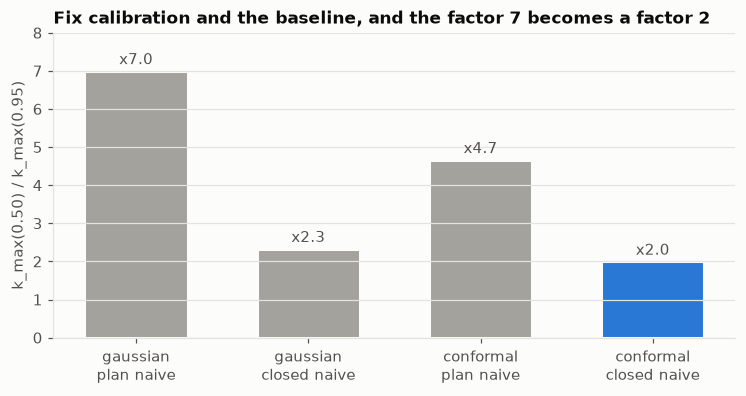

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.6))
labels, ratios = [], []
for (meth, bn), v in out["k_max"].items():
    labels.append(f"{meth}\n{'plan naive' if bn == 'snaive' else 'closed naive'}")
    ratios.append(v[0.5] / v[0.95])
colors = [viz.MUTED, viz.MUTED, viz.MUTED, viz.BLUE]
bars = ax.bar(labels, ratios, color=colors, width=0.6, edgecolor=viz.SURFACE, linewidth=2)
ax.bar_label(bars, labels=[f"x{r:.1f}" for r in ratios], padding=2, color=viz.TEXT_2)
ax.grid(axis="x", visible=False)
ax.set_ylabel("k_max(0.50) / k_max(0.95)"); ax.set_ylim(0, 8)
ax.set_title("Fix calibration and the baseline, and the factor 7 becomes a factor 2")
export(fig, "kmax_ratio_four_ways"); plt.show()

> **Takeaway.** The plan's factor 7 (gaussian quantiles, plan naive) needs both artefacts. Fixing the baseline
> alone gives 2.3; fixing both gives **2.0, with $k_{max}(0.95) = 168$ hours on all five seeds**. Fixing only the
> calibration gives 4.7, but that number is unstable: $k_{max}(0.95)$ ranges from 12 to 48 across seeds.
> So on this DGP the freshness budget does depend on the served quantile, by a factor of about two, not seven.
> The two Zanotti papers of block 1 point the same way, with the same modest size: probabilistic objectives want
> somewhat more frequent retraining than point ones.

## 6. The stability clause depends on the quantile machinery

**Question.** If the contract caps how much a published forecast may move, which cadences can sign it?

Two measures of stability, both at $\tau = 0.95$ and relative to the series' scale:

- **jump p95**: when a published quantile is revised, how big is a large revision (95th percentile of the
  non-zero revisions)?
- **visible revisions**: on what share of origins does the forecast for a given hour move by more than 1% of the
  scale?

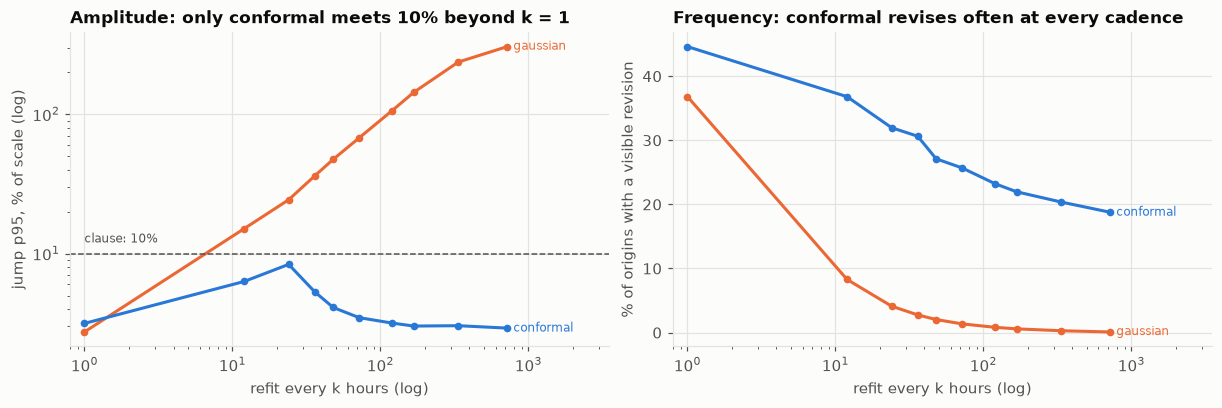

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
for meth, c in (("gaussian", viz.ORANGE), ("conformal", viz.BLUE)):
    jp = [100 * out["stability"][meth][k]["jump_p95"] for k in fs.KS]
    vis = [100 * out["stability"][meth][k]["pct_visible"] for k in fs.KS]
    axs[0].plot(ks, jp, color=c, marker="o", ms=4)
    axs[0].text(ks[-1] * 1.1, jp[-1], meth, color=c, fontsize=8, va="center")
    axs[1].plot(ks, vis, color=c, marker="o", ms=4)
    axs[1].text(ks[-1] * 1.1, vis[-1], meth, color=c, fontsize=8, va="center")
axs[0].axhline(10, color=viz.TEXT_2, ls="--", lw=1); axs[0].text(1, 12, "clause: 10%", color=viz.TEXT_2, fontsize=8)
axs[0].set_yscale("log"); axs[0].set_ylabel("jump p95, % of scale (log)")
axs[0].set_title("Amplitude: only conformal meets 10% beyond k = 1")
axs[1].set_ylabel("% of origins with a visible revision")
axs[1].set_title("Frequency: conformal revises often at every cadence")
for a in axs:
    a.set_xscale("log"); a.set_xlim(0.8, 3500); a.set_xlabel("refit every k hours (log)")
export(fig, "stability_by_quantile_method"); plt.show()

> **Takeaway.** With gaussian quantiles only continuous refits keep the 95th-percentile jump under 10% of the
> scale (2.7% at $k = 1$, 24% at $k = 24$, 305% at $k = 720$). With conformal quantiles every cadence meets it
> (2.9% to 8.4%), but the quantile is recalibrated every 24 hours, so 19% to 45% of origins carry a visible
> revision. **The stability clause is a property of the cadence *and* of the quantile method**, and the two
> clauses (amplitude, frequency) still pull in opposite directions: sign one of them.

## Side note: the closing-lag illusion at the 95th percentile

In [12]:
show(["quantiles", "k", "pinball with d = 48", "leaky backtest d = 0", "illusion"],
     [(m, k, f"{r:.4f}", f"{lk:.4f}", f"{ill:+.1%}") for (m, k), (r, lk, ill) in out["illusion"].items()])

| quantiles | k | pinball with d = 48 | leaky backtest d = 0 | illusion |
|---|---|---|---|---|
| gaussian | 24 | 0.0757 | 0.0672 | +12.5% |
| gaussian | 168 | 0.0888 | 0.0811 | +9.6% |
| conformal | 24 | 0.0750 | 0.0660 | +13.7% |
| conformal | 168 | 0.0794 | 0.0699 | +13.6% |

A backtest that pretends the actuals are closed immediately looks 10% to 14% better at the 95th percentile. Same
mechanism as block 2, larger at the tail.

**What to keep from this notebook.**
1. Before reading a tail result, check the tail's coverage: an under-covered quantile makes staleness look worse
   at the tail than it is.
2. The closing lag applies to every competitor, the baseline included.
3. Corrected, the freshness budget depends on the quantile by a factor of about 2 on this simulation. Notebook 2
   asks the same question on real electricity data.